# Diagnóstico: "ilhas" na camada zona × município

Nos municípios com mais de uma zona eleitoral, a zona é estimada juntando setores
censitários: cada setor vai à zona que recebe a maior parte dos seus adultos
(etapa 03, `alocacao.constroi_zona_mun`). Como o setor vai inteiro, perto da
fronteira entre as áreas de atração de dois locais de votação alguns setores
ficam do lado oposto ao dos vizinhos — as "ilhas".

Cada zona estimada é quebrada nas suas partes contínuas, e cada parte é
classificada assim:

- **principal**: a parte com mais eleitores da própria zona (desempate pela área);
- **ilha sem local**: parte secundária sem nenhum local de votação da própria
  zona dentro, encostada em outra zona — artefato da regra de maioria;
- **ilha sem local nem zona vizinha**: parte secundária sem local que não encosta
  em nenhuma outra zona — em geral ilha de verdade, no mar (Angra dos Reis, baías
  do Rio, Florianópolis);
- **parte com 1 local**: parte secundária com um local da própria zona dentro —
  em geral uma escola da zona X no meio da zona Y;
- **parte com 2+ locais**: parte secundária com vários locais da própria zona —
  em geral a zona cobre de fato dois territórios separados.

Eleitores = soma de `qt_eleitores` dos locais da própria zona dentro da parte.
Locais especiais (trânsito, presídio) e locais sem coordenada real (centróide do
município) ficam de fora.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
GEOM = RAIZ / "dados" / "03_georedus" / "geometrias"
PROC = RAIZ / "dados" / "02_processado"
CRS_METRICO = 5880  # SIRGAS 2000 / Brazil Polyconic

pd.set_option("display.max_colwidth", 60)
municipios = gpd.read_file(
    PROC / "aux" / "municipios.gpkg", columns=["cd_mun", "name_muni", "abbrev_state"], ignore_geometry=True
)
NOME_MUN = dict(zip(municipios.cd_mun, municipios.name_muni + "-" + municipios.abbrev_state))
CD_MUN = {v: k for k, v in NOME_MUN.items()}

## Classificação das partes

In [2]:
def carrega_locais(ano: int) -> gpd.GeoDataFrame:
    loc = gpd.read_file(GEOM / f"geom_locais_votacao_{ano}.gpkg").to_crs(CRS_METRICO)
    loc = loc.loc[~loc["flag_especial"] & ~loc["flag_sem_coord"]].copy()
    nomes = pd.read_parquet(PROC / f"locais_{ano}.parquet", columns=["id_local", "nm_local_votacao"])
    loc = loc.merge(nomes, on="id_local", how="left")
    loc["id_zona_mun"] = loc["cd_mun"] + loc["nr_zona"].astype(int).astype(str).str.zfill(4)
    return loc


def classifica_partes(caminho: Path, locais: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    """Uma linha por parte contínua de cada zona × município estimada."""
    zm = gpd.read_file(caminho).to_crs(CRS_METRICO)
    zm = zm.loc[zm["geom_estimada"]].explode(index_parts=False).reset_index(drop=True)
    zm["cd_mun"] = zm["id_zona_mun"].str[:7]
    zm["zona"] = zm["id_zona_mun"].str[7:].astype(int)
    zm["municipio"] = zm["cd_mun"].map(NOME_MUN)
    zm["area_km2"] = zm.area / 1e6

    j = gpd.sjoin(locais[["id_zona_mun", "qt_eleitores", "geometry"]], zm[["id_zona_mun", "geometry"]],
                  predicate="within")
    j = j.loc[j["id_zona_mun_left"] == j["id_zona_mun_right"]]
    zm["n_locais"] = j.groupby("index_right").size().reindex(zm.index, fill_value=0)
    zm["eleitores"] = j.groupby("index_right")["qt_eleitores"].sum().reindex(zm.index, fill_value=0)

    ordem = zm.sort_values(["id_zona_mun", "eleitores", "area_km2"], ascending=[True, False, False])
    principal = ~ordem["id_zona_mun"].duplicated()
    zm["categoria"] = np.select(
        [principal.reindex(zm.index), zm["n_locais"] == 0, zm["n_locais"] == 1],
        ["principal", "ilha sem local", "parte com 1 local"],
        default="parte com 2+ locais",
    )

    # zona que "cerca" cada parte secundária: a vizinha com mais fronteira em comum
    sec = zm.loc[zm["categoria"] != "principal"]
    viz = gpd.sjoin(sec[["cd_mun", "id_zona_mun", "geometry"]], zm[["cd_mun", "id_zona_mun", "geometry"]],
                    predicate="intersects")
    viz = viz.loc[(viz["cd_mun_left"] == viz["cd_mun_right"]) & (viz["id_zona_mun_left"] != viz["id_zona_mun_right"])]
    viz["fronteira_m"] = [
        a.boundary.intersection(zm.geometry[b].boundary).length for a, b in zip(viz.geometry, viz["index_right"])
    ]
    cerca = (viz.sort_values("fronteira_m", ascending=False)
                .loc[lambda d: ~d.index.duplicated()]["id_zona_mun_right"].str[7:].astype(int))
    zm["cercada_por"] = cerca.reindex(zm.index)
    sem_vizinha = (zm["categoria"] == "ilha sem local") & zm["cercada_por"].isna()
    zm.loc[sem_vizinha, "categoria"] = "ilha sem local nem zona vizinha"
    return zm


locais_2022 = carrega_locais(2022)
partes_2022 = classifica_partes(GEOM / "geom_zona_mun_2022_antes_ilhas.gpkg", locais_2022)
partes_2018 = classifica_partes(GEOM / "geom_zona_mun_2018_antes_ilhas.gpkg", carrega_locais(2018))

In [3]:
def resumo(partes: gpd.GeoDataFrame) -> pd.DataFrame:
    r = partes.groupby("categoria").agg(
        partes=("id_zona_mun", "size"),
        area_mediana_km2=("area_km2", "median"),
        eleitores_medianos=("eleitores", "median"),
        area_total_km2=("area_km2", "sum"),
    )
    r["pc_area"] = 100 * r["area_total_km2"] / partes["area_km2"].sum()
    return r.round(2)


print("2022"); display(resumo(partes_2022))
print("2018"); display(resumo(partes_2018))

2022


,partes,area_mediana_km2,eleitores_medianos,area_total_km2,pc_area
categoria,,,,,
ilha sem local,526,0.06,0.0,4129.05,1.06
ilha sem local nem zona vizinha,429,0.01,0.0,490.30,0.13
parte com 1 local,78,0.81,1690.5,14352.45,3.68
parte com 2+ locais,64,4.42,7599.5,22555.65,5.78
principal,721,54.42,100042.0,348590.04,89.36


2018


,partes,area_mediana_km2,eleitores_medianos,area_total_km2,pc_area
categoria,,,,,
ilha sem local,544,0.05,0.0,3874.69,0.99
ilha sem local nem zona vizinha,429,0.01,0.0,490.30,0.13
parte com 1 local,80,0.72,1491.0,12996.53,3.33
parte com 2+ locais,72,3.88,7775.5,22849.77,5.86
principal,721,53.12,94639.0,349906.21,89.69


Ilhas sem local, por tamanho (2022). A maioria é minúscula, mas algumas são áreas rurais grandes:

In [4]:
sem_local_2022 = partes_2022.loc[partes_2022["categoria"].str.startswith("ilha sem local")]
pd.crosstab(pd.cut(sem_local_2022["area_km2"], [0, 0.1, 1, 10, 1e6],
                   labels=["< 0,1 km²", "0,1 a 1 km²", "1 a 10 km²", "> 10 km²"]),
            sem_local_2022["categoria"])

categoria,ilha sem local,ilha sem local nem zona vizinha
area_km2,,
"< 0,1 km²",337,363
"0,1 a 1 km²",133,57
1 a 10 km²,39,6
> 10 km²,17,3


Municípios com mais partes secundárias (2022):

In [5]:
(partes_2022.loc[partes_2022["categoria"] != "principal"]
    .pivot_table(index="municipio", columns="categoria", values="id_zona_mun", aggfunc="size", fill_value=0)
    .assign(total=lambda d: d.sum(axis=1))
    .sort_values("total", ascending=False)
    .head(15))

categoria,ilha sem local,ilha sem local nem zona vizinha,parte com 1 local,parte com 2+ locais,total
municipio,,,,,
Rio de Janeiro-RJ,63,129,2,6,200
Angra dos Reis-RJ,1,151,1,1,154
São Paulo-SP,52,0,2,2,56
Santarém-PA,27,0,8,3,38
Vila Velha-ES,0,26,0,1,27
Florianópolis-SC,2,23,0,0,25
Salvador-BA,13,0,3,4,20
Niterói-RJ,5,13,0,1,19
São Gonçalo-RJ,10,8,0,0,18


## Exemplos

In [6]:
from shapely.geometry import box

CORES_ZONA = plt.get_cmap("tab20").colors


def acha_parte(partes, municipio, zona, categoria, cercada_por=None):
    sel = partes.loc[(partes["municipio"] == municipio) & (partes["zona"] == zona)
                     & (partes["categoria"] == categoria)]
    if cercada_por is not None:
        sel = sel.loc[sel["cercada_por"] == cercada_por]
    if sel.empty:
        raise ValueError(f"nenhuma parte: {municipio} zona {zona} {categoria} (cercada por {cercada_por})")
    return sel.sort_values(["eleitores", "area_km2"], ascending=False).index[0]


def mapa_parte(partes, locais, idx, ax, titulo=None, ponte=None, janela=None, cor=None):
    """Janela em volta da parte `idx`: zonas coloridas e rotuladas, a parte em
    destaque, locais de votação na cor da zona (nome dos que estão na parte)."""
    alvo = partes.loc[idx]
    if janela is None:
        minx, miny, maxx, maxy = alvo.geometry.bounds
        folga = max(1200, 1.2 * max(maxx - minx, maxy - miny))
        janela = (minx - folga, miny - folga, maxx + folga, maxy + folga)

    caixa = box(*janela)
    mun = gpd.clip(partes.loc[partes["cd_mun"] == alvo["cd_mun"]], caixa)
    loc = locais.loc[locais["cd_mun"] == alvo["cd_mun"]].cx[janela[0]:janela[2], janela[1]:janela[3]]
    # cores pelas zonas visíveis nesta janela (a paleta repete a cada 20; pelo
    # número da zona, 119 e 179 sairiam iguais)
    if cor is None:
        zonas = sorted(set(mun["zona"]) | set(loc["nr_zona"].astype(int)))
        cor = {z: CORES_ZONA[i % len(CORES_ZONA)] for i, z in enumerate(zonas)}
    cor_zona = lambda z: cor.get(int(z), "#cccccc")
    mun.plot(ax=ax, color=[cor_zona(z) for z in mun["zona"]], edgecolor="white", linewidth=0.6, alpha=0.75)
    gpd.GeoSeries([alvo.geometry], crs=partes.crs).boundary.plot(ax=ax, color="black", linewidth=2.2)
    if ponte is not None and not ponte.empty:
        ponte.plot(ax=ax, facecolor="none", edgecolor="#d03b3b", linewidth=1.6, hatch="////", linestyle="--")

    # rótulo de zona: um por zona, no maior pedaço visível na janela
    visiveis = mun.assign(a=mun.area).sort_values("a", ascending=False).drop_duplicates("zona")
    for _, p in visiveis.loc[visiveis["a"] > 0.01 * caixa.area].iterrows():
        pt = p.geometry.representative_point()
        ax.annotate(str(p["zona"]), (pt.x, pt.y), ha="center", fontsize=9, fontweight="bold", color="#0b0b0b")

    if not loc.empty:
        loc.plot(ax=ax, color=[cor_zona(z) for z in loc["nr_zona"]], edgecolor="black", linewidth=0.6, markersize=28)
    dentro = loc.loc[loc.within(alvo.geometry) & (loc["id_zona_mun"] == alvo["id_zona_mun"])]
    for _, l in dentro.head(3).iterrows():
        ax.annotate(str(l["nm_local_votacao"]).title()[:30], (l.geometry.x, l.geometry.y), xytext=(4, 4),
                    textcoords="offset points", fontsize=6.5)

    ax.set_xlim(janela[0], janela[2]); ax.set_ylim(janela[1], janela[3])
    ax.set_xticks([]); ax.set_yticks([])
    em_volta = f"dentro da {alvo['cercada_por']:.0f}" if pd.notna(alvo["cercada_por"]) else "sem zona vizinha"
    ax.set_title(titulo or (f"{alvo['municipio']} · zona {alvo['zona']} {em_volta}\n"
                            f"{alvo['categoria']} · {alvo['area_km2']:.2f} km² · {alvo['n_locais']} local(is) · "
                            f"{alvo['eleitores']:,.0f} eleitores".replace(",", ".")), fontsize=9)
    return janela, cor


def grade(partes, locais, indices, titulo):
    fig, eixos = plt.subplots(1, len(indices), figsize=(5.2 * len(indices), 5.2))
    for ax, i in zip(np.atleast_1d(eixos), indices):
        mapa_parte(partes, locais, i, ax)
    fig.suptitle(titulo, fontsize=12, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

### Ilhas sem local da própria zona (artefato)

O primeiro é o caso que motivou a revisão: 3 setores da zona 251 dentro da 374, em
São Paulo. Nesses setores o CNEFE só tem endereços de domicílio coletivo e de
estabelecimentos, e o local mais próximo deles é o Colégio Santa Cruz (zona 251).
Os outros dois são sorteados entre as ilhas de tamanho típico (entre os quartis
de área), no Rio de Janeiro e fora dele.

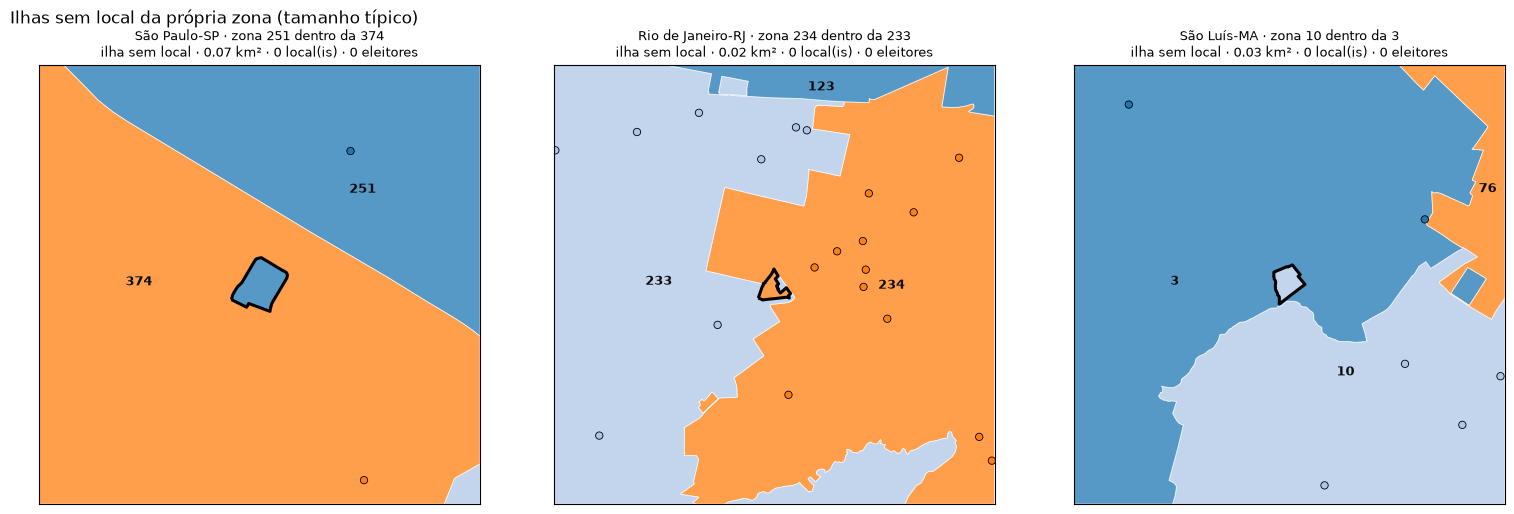

In [7]:
sem_local = partes_2022.loc[partes_2022["categoria"] == "ilha sem local"]
q1, q3 = sem_local["area_km2"].quantile([0.25, 0.75])
tipicas = sem_local.loc[sem_local["area_km2"].between(q1, q3)]
ex_sem_local = [
    acha_parte(partes_2022, "São Paulo-SP", 251, "ilha sem local", cercada_por=374),
    tipicas.loc[tipicas["municipio"] == "Rio de Janeiro-RJ"].sample(1, random_state=1).index[0],
    tipicas.loc[~tipicas["municipio"].isin(["Rio de Janeiro-RJ", "São Paulo-SP"])].sample(1, random_state=1).index[0],
]
grade(partes_2022, locais_2022, ex_sem_local, "Ilhas sem local da própria zona (tamanho típico)")

### Ilhas sem local grandes

Poucas, mas grandes: áreas rurais sem nenhum local da zona, que foram parar nela
pela regra do local mais próximo (setores sem domicílio) ou pela maioria dos
adultos. A correção passa essas áreas para a zona vizinha com mais fronteira em
comum — também uma estimativa, mas sem deixar pedaços soltos.

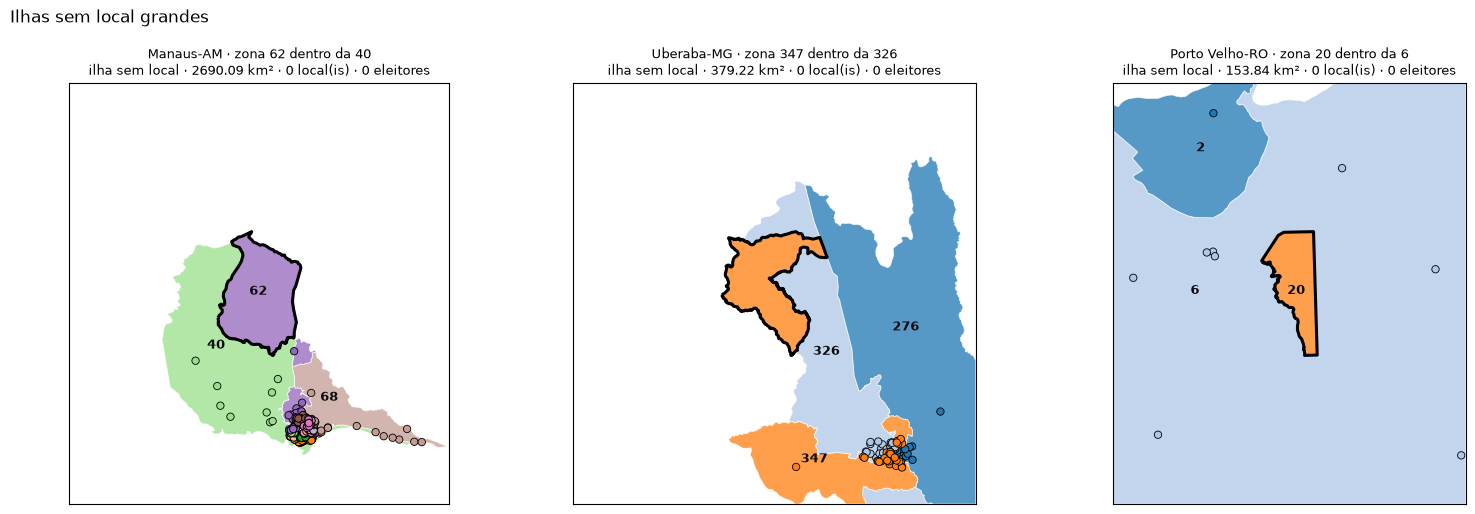

In [8]:
ex_grandes = list(sem_local.sort_values("area_km2", ascending=False).drop_duplicates("municipio").index[:3])
grade(partes_2022, locais_2022, ex_grandes, "Ilhas sem local grandes")

### Ilhas sem local nem zona vizinha

Não encostam em nenhuma outra zona — em geral ilhas de verdade, no mar. A correção
não mexe nelas (não há fronteira para decidir a zona).

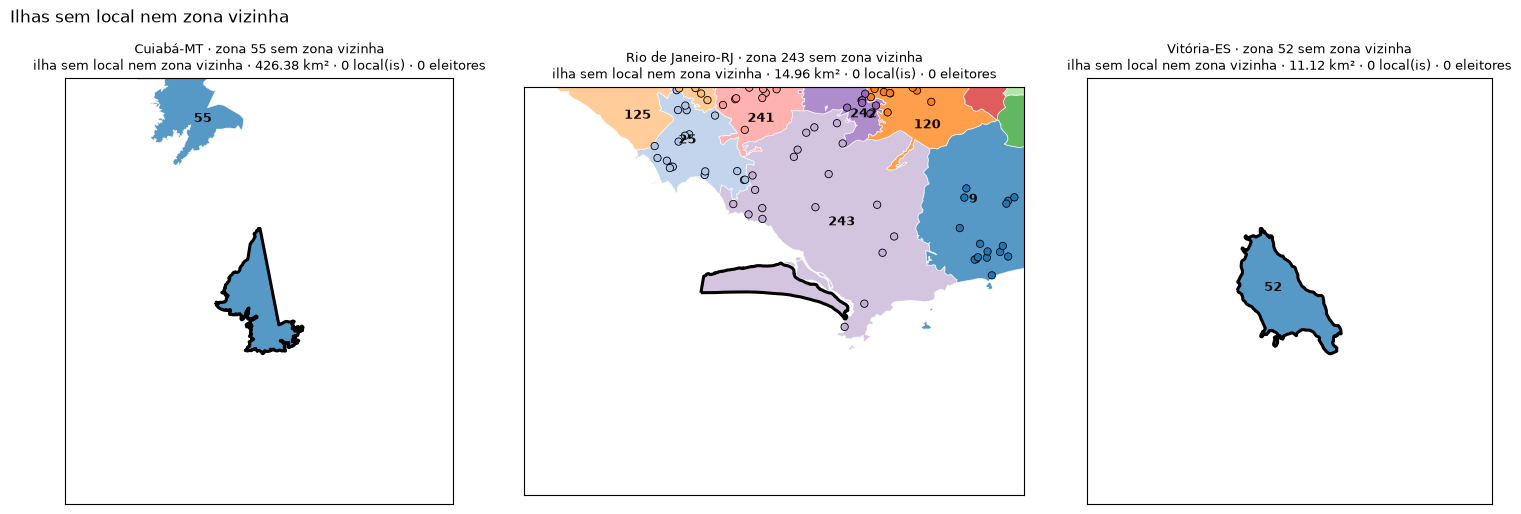

In [9]:
sem_vizinha = partes_2022.loc[partes_2022["categoria"] == "ilha sem local nem zona vizinha"]
ex_sem_vizinha = list(sem_vizinha.sort_values("area_km2", ascending=False).drop_duplicates("municipio").index[:3])
grade(partes_2022, locais_2022, ex_sem_vizinha, "Ilhas sem local nem zona vizinha")

### Partes com 1 local da própria zona

Uma escola da zona X fica dentro do território da zona Y, e os setores em volta
votam nela.

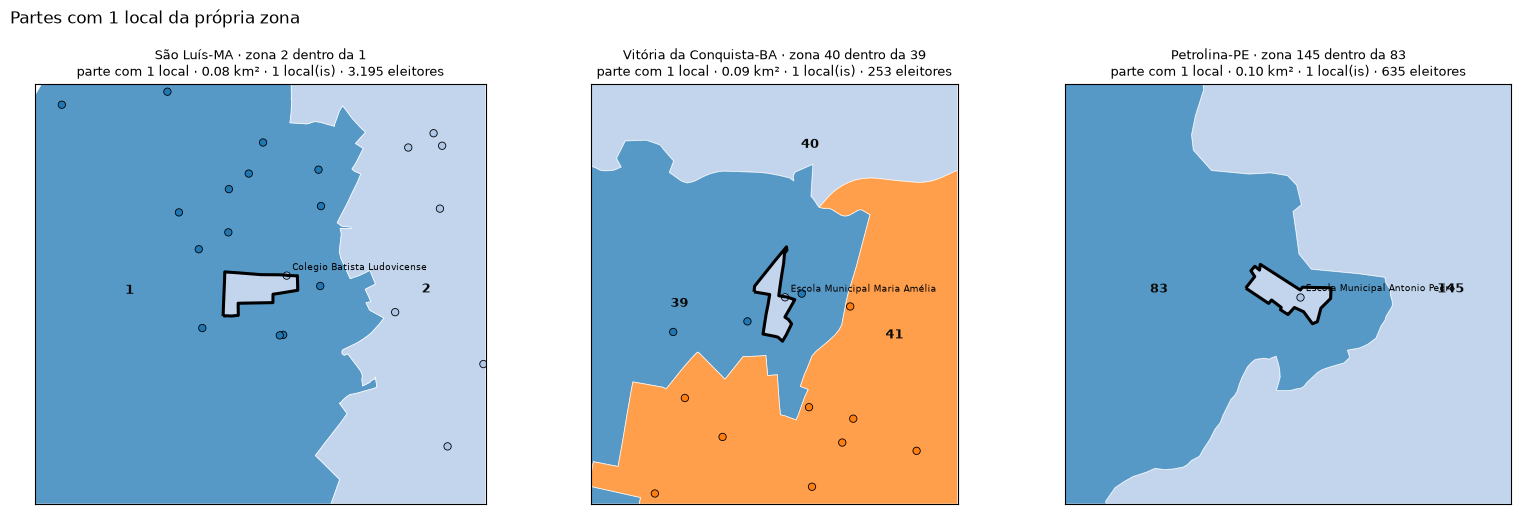

In [10]:
ex_1_local = [
    acha_parte(partes_2022, "São Luís-MA", 2, "parte com 1 local", cercada_por=1),
    acha_parte(partes_2022, "Vitória da Conquista-BA", 40, "parte com 1 local", cercada_por=39),
    acha_parte(partes_2022, "Petrolina-PE", 145, "parte com 1 local", cercada_por=83),
]
grade(partes_2022, locais_2022, ex_1_local, "Partes com 1 local da própria zona")

### Pontes: setores que ligariam as partes com 1 local ao resto da zona

Para cada parte com 1 local, o caminho de setores vizinhos até a parte principal da
própria zona que atravessa menos adultos (Dijkstra no grafo de vizinhança dos
setores; o custo de entrar num setor é o número de adultos dele). Os setores desse
caminho são a "ponte": hoje estão em outra zona e, se passassem para esta, a zona
ficaria contínua.

Mudar a zona desses setores não altera nenhum voto estimado por setor (a matriz de
pesos vai de local para setor e não depende da zona); só a fronteira estimada
muda.

In [11]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra

import sys
sys.path.insert(0, str(RAIZ / "src"))
from eleicoes.config import SETORES_2022_GPKG

pesos_2022 = pd.read_parquet(RAIZ / "dados/03_georedus/resultados/pesos_local_setor_2022.parquet")
adultos_setor = pesos_2022.groupby("cd_setor")["adultos"].sum()


def setores_com_parte(partes, municipios):
    """Setores dos municípios, com a zona e a parte (pelo ponto interior) e os adultos."""
    where = "CD_MUN IN (" + ",".join(f"'{m}'" for m in municipios) + ")"
    s = gpd.read_file(SETORES_2022_GPKG, where=where, columns=["CD_SETOR", "CD_MUN"])
    s = s.rename(columns={"CD_SETOR": "cd_setor", "CD_MUN": "cd_mun"}).to_crs(CRS_METRICO)
    s["adultos"] = s["cd_setor"].map(adultos_setor).fillna(0)
    pts = s[["cd_setor", "geometry"]].copy()
    pts["geometry"] = pts.geometry.representative_point()
    j = gpd.sjoin(pts, partes[["id_zona_mun", "geometry"]], predicate="within").drop_duplicates("cd_setor")
    return s.merge(j[["cd_setor", "id_zona_mun", "index_right"]].rename(columns={"index_right": "parte"}),
                   on="cd_setor", how="left")


def pontes(partes, setores, indices):
    """Para cada parte em `indices`: os setores da ponte mais barata (em adultos)."""
    saida = []
    for cd_mun, idx_mun in partes.loc[indices].groupby("cd_mun").groups.items():
        s = setores.loc[setores["cd_mun"] == cd_mun].reset_index(drop=True)
        viz = gpd.sjoin(s[["geometry"]], s[["geometry"]], predicate="intersects")
        viz = viz.loc[viz.index < viz["index_right"]]
        borda = np.array([s.geometry[a].boundary.intersection(s.geometry[b].boundary).length
                          for a, b in zip(viz.index, viz["index_right"])])
        viz = viz.loc[borda > 1]  # contato só num ponto não conta
        a, b = viz.index.to_numpy(), viz["index_right"].to_numpy()
        custo = s["adultos"].to_numpy() + 1
        g = csr_matrix((np.r_[custo[b], custo[a]], (np.r_[a, b], np.r_[b, a])), shape=(len(s), len(s)))
        for idx in idx_mun:
            p = partes.loc[idx]
            principal = partes.index[(partes["id_zona_mun"] == p["id_zona_mun"]) & (partes["categoria"] == "principal")]
            origem = s.index[s["parte"] == idx].to_numpy()
            destino = s.index[s["parte"].isin(principal)].to_numpy()
            if len(origem) == 0 or len(destino) == 0:
                continue
            dist, pred, _ = dijkstra(g, indices=origem, min_only=True, return_predecessors=True)
            k = destino[np.argmin(dist[destino])]
            if not np.isfinite(dist[k]):
                continue
            caminho, v = [], pred[k]
            while v >= 0 and v not in set(origem):
                caminho.append(v)
                v = pred[v]
            ponte = s.loc[caminho]
            saida.append({
                "parte": idx, "municipio": p["municipio"], "zona": p["zona"], "cercada_por": p["cercada_por"],
                "eleitores_da_parte": p["eleitores"], "setores_na_ponte": len(ponte),
                "adultos_na_ponte": round(ponte["adultos"].sum()),
                "distancia_m": round(partes.geometry[idx].distance(partes.loc[principal].geometry.union_all())),
                "geometria_ponte": ponte.geometry.union_all() if len(ponte) else None,
            })
    return pd.DataFrame(saida).set_index("parte")


um_local = partes_2022.index[partes_2022["categoria"] == "parte com 1 local"]
setores_1_local = setores_com_parte(partes_2022, partes_2022.loc[um_local, "cd_mun"].unique())
pontes_1_local = pontes(partes_2022, setores_1_local, um_local)
pd.cut(pontes_1_local["setores_na_ponte"], [0, 1, 2, 3, 5, 1000],
       labels=["1 setor", "2", "3", "4 a 5", "6 ou mais"]).value_counts().sort_index().rename("partes")

setores_na_ponte
1 setor      30
2            16
3             3
4 a 5         9
6 ou mais    18
Name: partes, dtype: int64

In [12]:
(pontes_1_local.drop(columns="geometria_ponte")
    .sort_values(["setores_na_ponte", "adultos_na_ponte"]).reset_index(drop=True))

,municipio,zona,cercada_por,eleitores_da_parte,setores_na_ponte,adultos_na_ponte,distancia_m
0,Castanhal-PA,50,4.0,161.0,1,0,1116
1,Santarém-PA,83,104.0,88.0,1,0,2592
2,Araguaína-TO,34,1.0,510.0,1,0,2081
3,Recife-PE,1,4.0,1798.0,1,0,79
4,Vitória de Santo Antão-PE,102,18.0,3281.0,1,0,1513
...,...,...,...,...,...,...,...
71,Santarém-PA,83,20.0,820.0,14,580,477
72,Goiânia-GO,127,134.0,3019.0,14,3340,12135
73,Santarém-PA,20,104.0,177.0,16,212,57981
74,Salvador-BA,8,13.0,5771.0,17,3109,7918


Os dois exemplos: Vitória da Conquista (zona 40) e Petrolina (zona 145). A ponte está hachurada em vermelho.

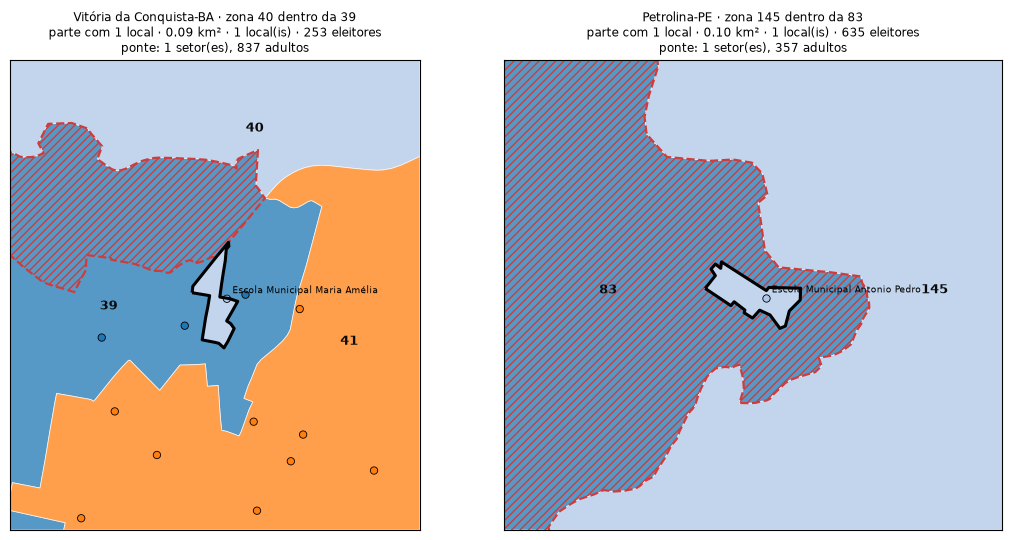

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, idx in zip(eixos, ex_1_local[1:3]):
    ponte = gpd.GeoSeries([pontes_1_local.loc[idx, "geometria_ponte"]], crs=partes_2022.crs)
    mapa_parte(partes_2022, locais_2022, idx, ax, ponte=ponte)
    ax.set_title(ax.get_title() + f"\nponte: {pontes_1_local.loc[idx, 'setores_na_ponte']} setor(es), "
                 f"{pontes_1_local.loc[idx, 'adultos_na_ponte']} adultos", fontsize=8.5)
fig.tight_layout()
plt.show()

### Partes com 2 ou mais locais da própria zona

Em geral a zona cobre de fato dois territórios separados (ex.: um distrito
afastado ou uma área rural atendida pela zona do centro).

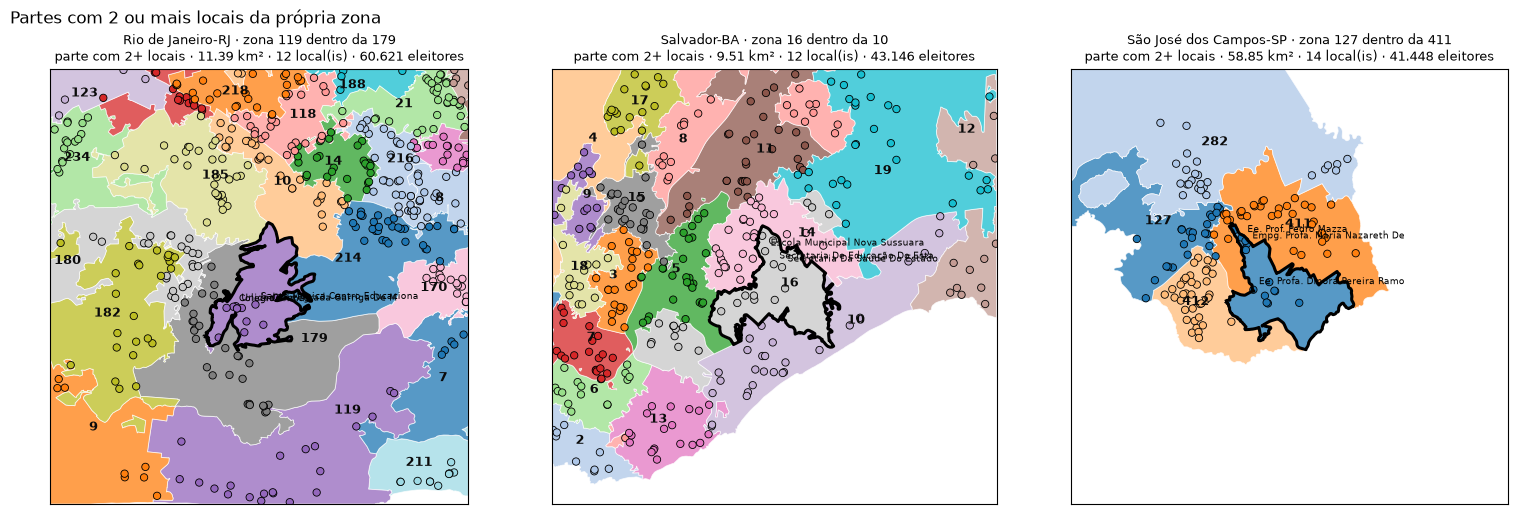

In [14]:
# as três maiores (por eleitores), cada uma de um município
ex_2_locais = list(partes_2022.loc[partes_2022["categoria"] == "parte com 2+ locais"]
                   .sort_values("eleitores", ascending=False)
                   .drop_duplicates("municipio").index[:3])
grade(partes_2022, locais_2022, ex_2_locais, "Partes com 2 ou mais locais da própria zona")

## Depois da correção

Regra aplicada em `alocacao._torna_zonas_continuas` (decisões de 30/09/2026):

- **ilha sem local da própria zona**: passa para a zona vizinha com quem divide a
  maior fronteira; se não encosta em nenhuma zona (ilha no mar), fica;
- **parte com 1 local**: é ligada ao corpo da zona pela ponte de setores de menos
  inscritos, se nenhuma zona envolvida mudar a soma estimada de inscritos em mais
  de 5% da soma real (inscritos dos locais da zona);
- **parte com 2 ou mais locais**: fica.

Além disso, os locais posicionados no centróide do município saíram da alocação
dos domicílios. Esta seção compara a geometria guardada antes da correção
(`geom_zona_mun_{ano}_antes_ilhas.gpkg`) com a atual.

In [15]:
import filecmp

atual = GEOM / "geom_zona_mun_2022.gpkg"
antes = GEOM / "geom_zona_mun_2022_antes_ilhas.gpkg"
CORRIGIDO = not filecmp.cmp(atual, antes, shallow=False)
if CORRIGIDO:
    partes_depois = classifica_partes(atual, locais_2022)
    comp = pd.concat({"antes": resumo(partes_2022)["partes"], "depois": resumo(partes_depois)["partes"]}, axis=1)
    display(comp.fillna(0).astype(int))
else:
    print("A correção ainda não rodou: a geometria atual é igual à de antes.")

,antes,depois
categoria,,
ilha sem local,526,15
ilha sem local nem zona vizinha,429,429
parte com 1 local,78,31
parte com 2+ locais,64,61
principal,721,721


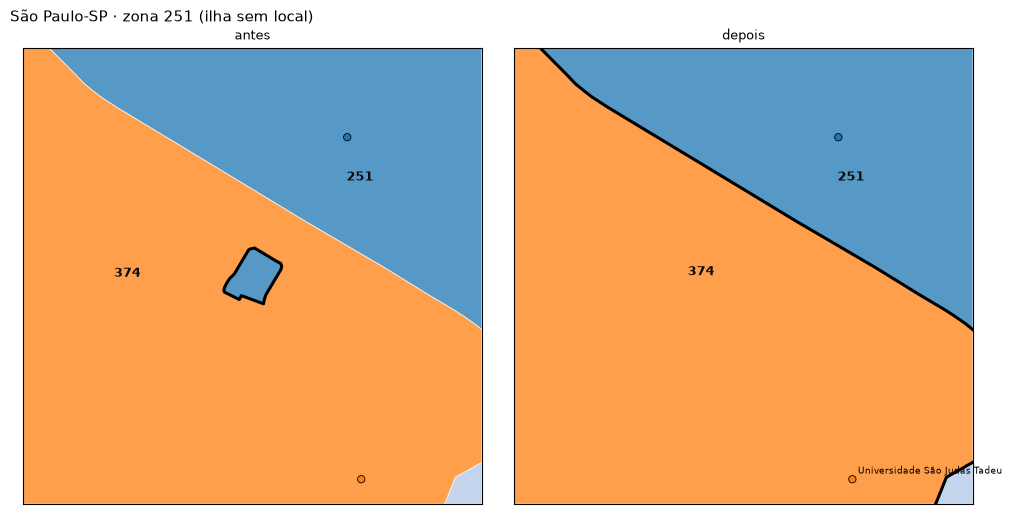

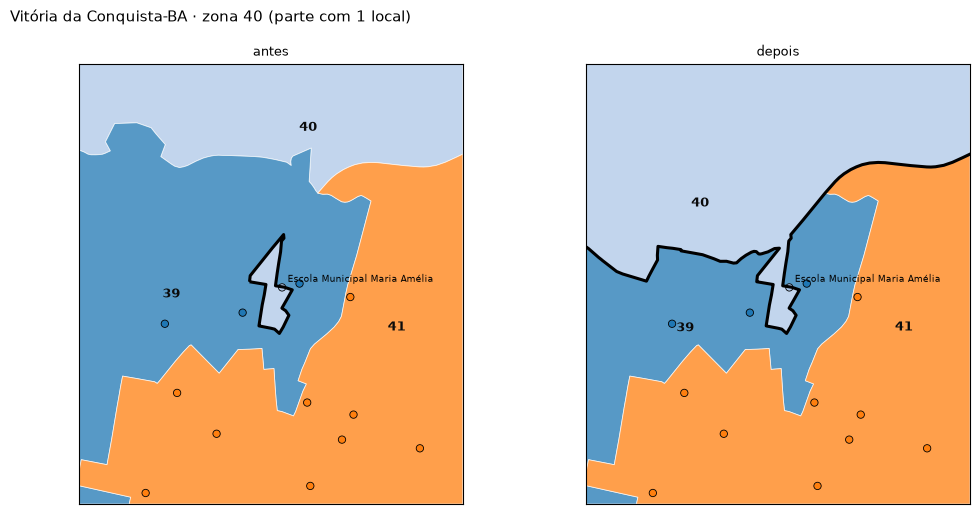

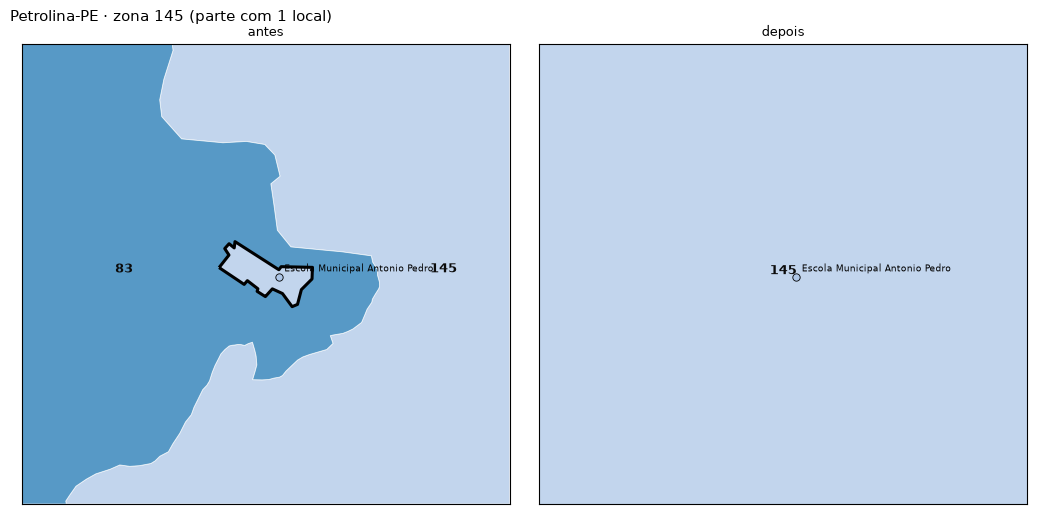

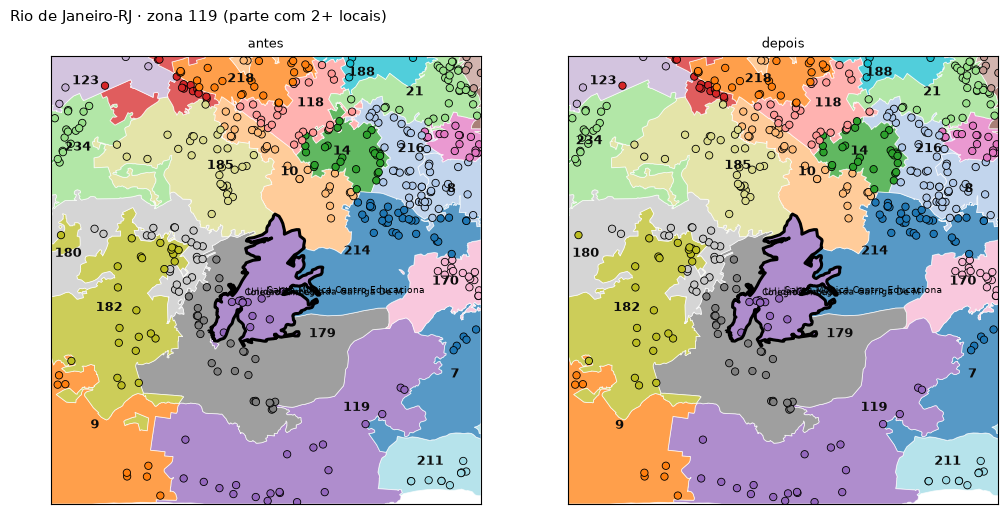

In [16]:
def antes_depois(idx_antes, titulo):
    alvo = partes_2022.loc[idx_antes]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 5.2))
    janela, cor = mapa_parte(partes_2022, locais_2022, idx_antes, a1, titulo="antes")
    # mesma janela e mesmas cores; em destaque, a parte que hoje contém o ponto
    # da antiga (ela pode ter sido absorvida ou ligada ao corpo da zona)
    candidatos = partes_depois.loc[(partes_depois["cd_mun"] == alvo["cd_mun"])]
    ref = candidatos.loc[candidatos.intersects(alvo.geometry.representative_point())].index[0]
    mapa_parte(partes_depois, locais_2022, ref, a2, titulo="depois", janela=janela, cor=cor)
    fig.suptitle(titulo, fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()


if CORRIGIDO:
    for i in ex_sem_local[:1] + ex_1_local[1:3] + ex_2_locais[:1]:
        p = partes_2022.loc[i]
        antes_depois(i, f"{p['municipio']} · zona {p['zona']} ({p['categoria']})")